In [9]:
# %pip install xlrd
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_excel(
    "/workspace/data/sample_-_superstore.xls",
    sheet_name="Orders"
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

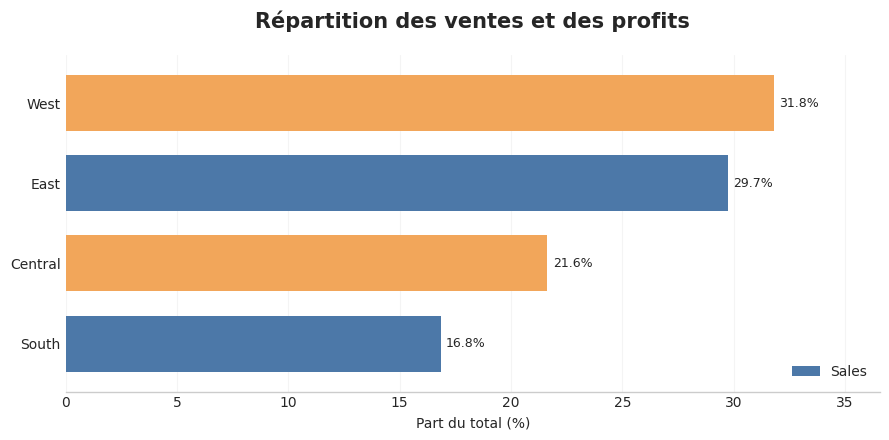

In [42]:
import matplotlib.pyplot as plt

# Style général
plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(9, 4.5))

# Graphique avec deux séries
parts.plot.barh(
    ax=ax,
    width=0.7,
    color=["#4C78A8", "#F2A65A"]
)

# Titres
ax.set_title(
    "Répartition des ventes et des profits",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Part du total (%)")
ax.set_ylabel("")

# Affichage des valeurs sur les barres
for barres in ax.containers:
    ax.bar_label(barres, fmt="%.1f%%", padding=4, fontsize=9)

# Mise en forme
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.legend(frameon=False, loc="lower right")
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

In [10]:
print(orders.shape)
print(orders.columns.tolist())

(10194, 21)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [11]:
print('Lignes :', len(orders)) # articles commandés 
print('Commandes distinctes :', orders['Order ID'].nunique()) # nombre de commande 
print('Catégories :', orders['Category'].nunique())

Lignes : 10194
Commandes distinctes : 5111
Catégories : 3


In [19]:
pd.DataFrame(
    orders["Category"].unique(),
    columns=["Catégorie"]
).style.hide(axis="index")

Catégorie
Office Supplies
Furniture
Technology


In [21]:
print(orders['Region'].nunique())
print(orders['Category'].nunique())
print(orders['Sub-Category'].nunique())

4
3
17


In [26]:
par_categorie = orders.groupby("Category")["Order ID"].agg(
    lignes="size",
    commandes="nunique"
)

par_categorie = par_categorie.sort_values("lignes")

print(par_categorie)

                 lignes  commandes
Category                          
Technology         1865       1560
Furniture          2201       1819
Office Supplies    6128       3812


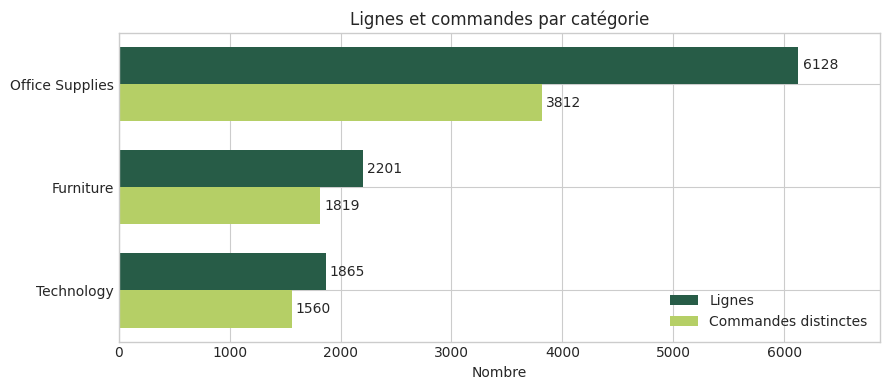

In [43]:
# Création d'une figure et de ses axes
# figsize définit la largeur et la hauteur en pouces
fig, ax = plt.subplots(figsize=(9, 4))

# Positions verticales des catégories : 0, 1, 2...
y = range(len(par_categorie))

# Première série : nombre de lignes par catégorie
# +0.18 décale les barres vers le bas
# height définit l'épaisseur des barres
b1 = ax.barh(
    [i + 0.18 for i in y],
    par_categorie["lignes"],
    height=0.36,
    label="Lignes",
    color="#275c47"
)

# Deuxième série : nombre de commandes distinctes
# -0.18 décale les barres vers le haut
b2 = ax.barh(
    [i - 0.18 for i in y],
    par_categorie["commandes"],
    height=0.36,
    label="Commandes distinctes",
    color="#b5cf66"
)

# Affichage des valeurs numériques au bout des barres
# padding=3 définit un espacement de 3 points
ax.bar_label(b1, padding=3)
ax.bar_label(b2, padding=3)

# Remplacement des positions 0, 1, 2...
# par les véritables noms des catégories
ax.set_yticks(list(y), par_categorie.index)

# Titre du graphique et nom de l'axe horizontal
ax.set(
    title="Lignes et commandes par catégorie",
    xlabel="Nombre"
)

# Affichage de la légende
ax.legend()

# Ajout d'une marge horizontale de 12 %
# pour laisser de la place aux valeurs affichées
ax.margins(x=0.12)

# Ajustement automatique des espacements
plt.tight_layout()

# Affichage du graphique
plt.show()

In [30]:
par_region = orders.groupby('Region')["Order ID"].agg(lignes='size', commandes='nunique')
# Compléter avec le calcul de l'écart puis identifier le maximum

In [31]:
par_region

,lignes,commandes
Region,,
Central,2335,1179
East,2986,1475
South,1620,822
West,3253,1635


In [35]:
commandes_annee = orders.groupby(orders['Order Date'].dt.year)['Order ID'].nunique().sort_index()
print(commandes_annee)

Order Date
2023     995
2024    1053
2025    1340
2026    1723
Name: Order ID, dtype: int64


In [36]:
ventes = orders.groupby('Category')['Sales'].sum()
print(ventes)

Category
Furniture          754747.7613
Office Supplies    731893.3140
Technology         839893.2790
Name: Sales, dtype: float64


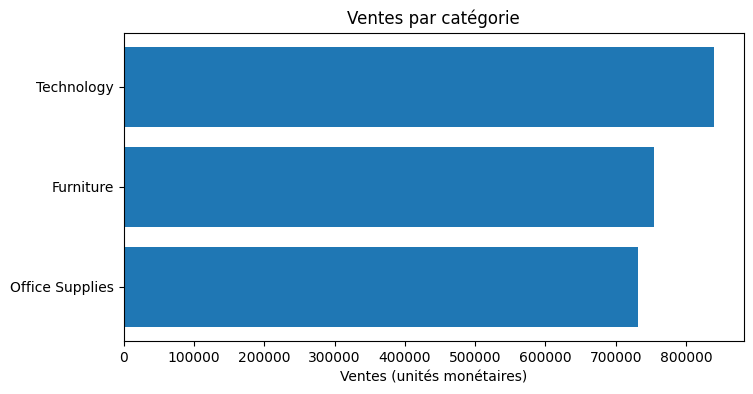

In [37]:
ventes = ventes.sort_values()
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(ventes.index, ventes.values)
ax.set(title='Ventes par catégorie', xlabel='Ventes (unités monétaires)')
plt.show()

2326534.3543000002


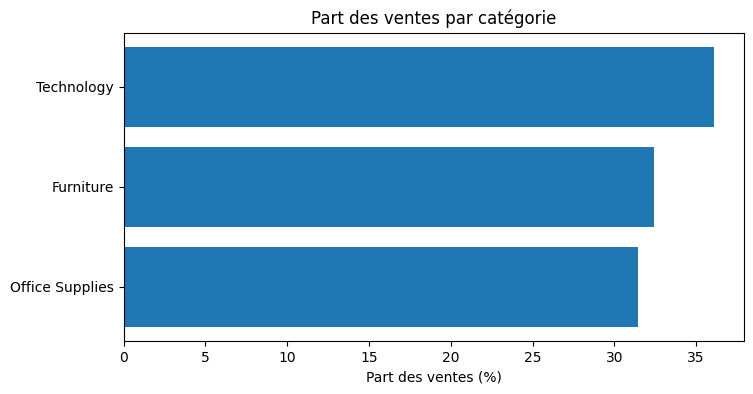

In [39]:
ventes = orders.groupby('Category')['Sales'].sum()
total = ventes.sum()
print(total)

part = ventes / total * 100
part = part.sort_values()
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(part.index, part.values)
ax.set(title='Part des ventes par catégorie', xlabel='Part des ventes (%)')
plt.show()


In [40]:
# Chiffre d'affaires par région
ventes = orders.groupby("Region")["Sales"].sum()

# Chiffre d'affaires total
total = ventes.sum()

# Calcul des pourcentages, triés par ordre croissant
parts = (ventes / total * 100).sort_values()

print(parts.round(2))

Region
South      16.84
Central    21.63
East       29.74
West       31.80
Name: Sales, dtype: float64


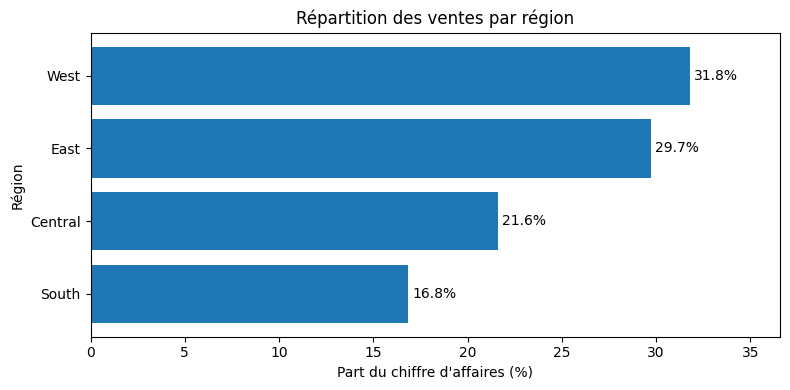

In [41]:
fig, ax = plt.subplots(figsize=(8, 4))

# Graphique à barres horizontales
barres = ax.barh(parts.index, parts.values)

# Afficher les pourcentages au bout des barres
ax.bar_label(barres, fmt="%.1f%%", padding=3)

ax.set(
    title="Répartition des ventes par région",
    xlabel="Part du chiffre d'affaires (%)",
    ylabel="Région"
)

ax.set_xlim(0, parts.max() * 1.15)

plt.tight_layout()
plt.show()